# Seaborn – statistical charts in one line

**Video 8.3** · ShopKart project

**Goal:** Use seaborn to answer ShopKart questions quickly: how many orders per category (countplot), average revenue per category (barplot), does slow delivery mean more returns (boxplot), discount vs quantity (scatterplot with hue), and which numbers move together (correlation heatmap).

**How to open in Colab:** go to colab.research.google.com → File → Upload notebook → choose this file. Then click the folder icon on the left and drag these data files in: `shopkart_clean.csv`. Then run cells from top to bottom (Shift + Enter).

Seaborn is built on top of matplotlib. It takes the whole DataFrame and a column name – it does the groupby for you.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv("shopkart_clean.csv")
os.makedirs("images", exist_ok=True)

sns.set_theme(style="whitegrid")     # clean look for every seaborn chart
MAIN, HIGHLIGHT, GREY = "#2a78d6", "#eb6834", "#b8b6ae"
RETURN_COLORS = {"N": MAIN, "Y": HIGHLIGHT}   # same colour = same meaning in every chart
df.shape

(5000, 21)

## 1. countplot – how many orders in each category?
`countplot` counts rows. No groupby needed.

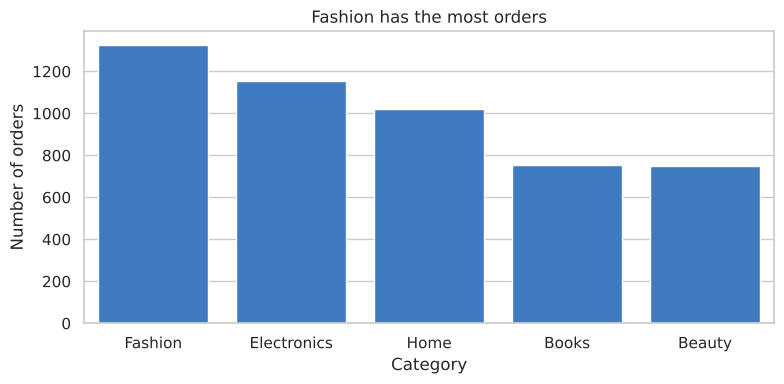

category
Fashion        1326
Electronics    1152
Home           1020
Books           752
Beauty          750
Name: count, dtype: int64

In [2]:
plt.figure(figsize=(8, 4))
order = df["category"].value_counts().index        # biggest first
sns.countplot(data=df, x="category", order=order, color=MAIN)
plt.title("Fashion has the most orders")
plt.xlabel("Category")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.savefig("images/M08_sns_countplot.png", dpi=150)
plt.show()
df["category"].value_counts()

## 2. countplot with hue – returns per category
`hue` splits each bar by another column. Here: returned Y / N.

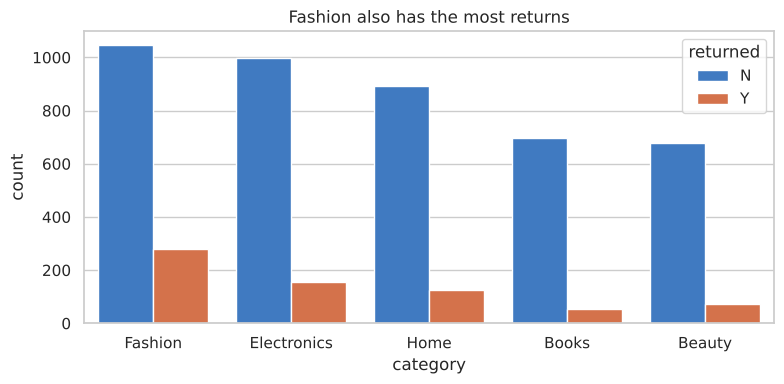

category
Fashion        21.0
Electronics    13.5
Home           12.5
Beauty          9.5
Books           7.3
Name: returned, dtype: float64

In [3]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="category", hue="returned", order=order, palette=RETURN_COLORS)
plt.title("Fashion also has the most returns")
plt.tight_layout()
plt.show()

# The return RATE is easier to compare than raw counts:
(df["returned"].eq("Y").groupby(df["category"]).mean() * 100).round(1).sort_values(ascending=False)

## 3. barplot – average revenue per order, by category
`barplot` shows the **average** (mean) by default. The thin black line on each bar is the *confidence interval* – roughly, how sure we are about that average. Electronics has a wide line because a few phone orders are very large.

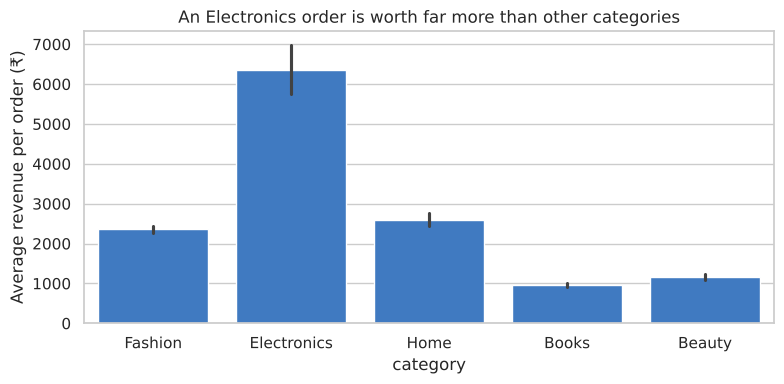

category
Electronics    6364.0
Home           2603.0
Fashion        2354.0
Beauty         1170.0
Books           957.0
Name: revenue, dtype: float64

In [4]:
plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="category", y="revenue", order=order, color=MAIN)
plt.title("An Electronics order is worth far more than other categories")
plt.ylabel("Average revenue per order (₹)")
plt.tight_layout()
plt.savefig("images/M08_sns_barplot.png", dpi=150)
plt.show()
df.groupby("category")["revenue"].mean().round(0).sort_values(ascending=False)

## 4. boxplot – are returned orders delivered more slowly?
Remember the box plot from Module 3: the line in the box is the median, the box is the middle 50% (IQR), the dots are outliers.

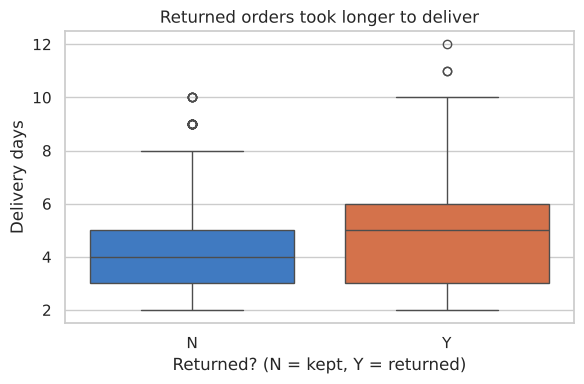

,median,mean
returned,,
N,4.0,4.08
Y,5.0,4.60


In [5]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="returned", y="delivery_days", hue="returned",
            palette=RETURN_COLORS, legend=False)
plt.title("Returned orders took longer to deliver")
plt.xlabel("Returned? (N = kept, Y = returned)")
plt.ylabel("Delivery days")
plt.tight_layout()
plt.savefig("images/M08_sns_boxplot.png", dpi=150)
plt.show()

df.groupby("returned")["delivery_days"].agg(["median", "mean"]).round(2)

## 5. scatterplot with hue – does a bigger discount mean people buy more?
Each dot is one order. Many orders share the same discount and quantity, so we add a little random 'jitter' so dots don't sit exactly on top of each other. Colour (hue) = membership.

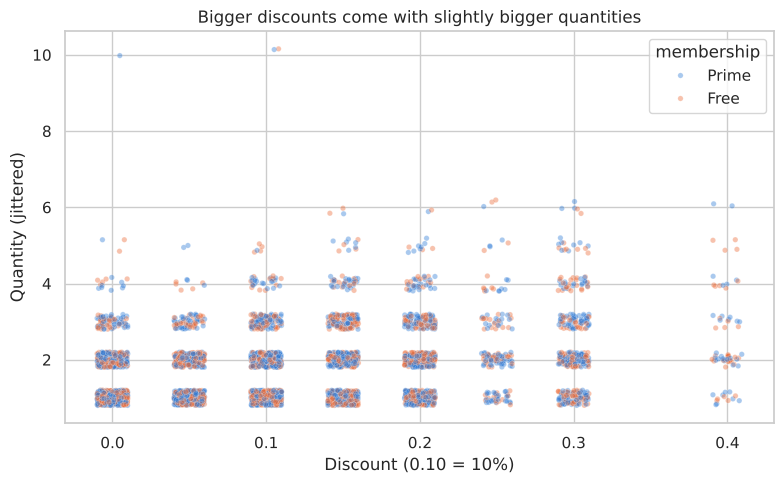

Correlation discount vs quantity: 0.27


In [6]:
import numpy as np
rng = np.random.default_rng(42)
plot_df = df.copy()
plot_df["discount_jitter"] = plot_df["discount"] + rng.uniform(-0.01, 0.01, len(df))
plot_df["quantity_jitter"] = plot_df["quantity"] + rng.uniform(-0.2, 0.2, len(df))

plt.figure(figsize=(8, 5))
sns.scatterplot(data=plot_df, x="discount_jitter", y="quantity_jitter", hue="membership",
                palette={"Prime": MAIN, "Free": HIGHLIGHT}, alpha=0.4, s=15)
plt.title("Bigger discounts come with slightly bigger quantities")
plt.xlabel("Discount (0.10 = 10%)")
plt.ylabel("Quantity (jittered)")
plt.tight_layout()
plt.savefig("images/M08_sns_scatter.png", dpi=150)
plt.show()

print("Correlation discount vs quantity:", round(df["discount"].corr(df["quantity"]), 2))

## 6. Correlation heatmap – which numbers move together?
`df.corr()` gives the correlation (−1 to +1) between every pair of numeric columns. A heatmap colours that table. Red-ish = move up together, blue-ish = one up, other down.

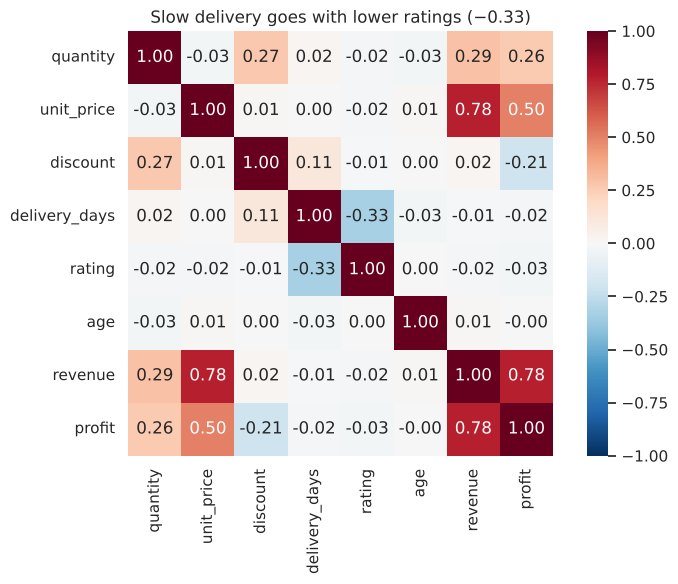

In [7]:
num_cols = ["quantity", "unit_price", "discount", "delivery_days", "rating", "age", "revenue", "profit"]
corr = df[num_cols].corr().round(2)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Slow delivery goes with lower ratings (−0.33)")
plt.tight_layout()
plt.savefig("images/M08_sns_heatmap.png", dpi=150)
plt.show()

In [8]:
# Read the three most interesting numbers straight from the table
print("delivery_days vs rating:", corr.loc["delivery_days", "rating"])
print("discount vs quantity   :", corr.loc["discount", "quantity"])
print("unit_price vs revenue  :", corr.loc["unit_price", "revenue"])

delivery_days vs rating: -0.33
discount vs quantity   : 0.27
unit_price vs revenue  : 0.78


**Remember (Module 3): correlation is not causation.** Slow delivery and low ratings move together – that is a strong *hint*, and a reason to test faster delivery, not proof.

## Your turn (practice)
Make a boxplot of `delivery_days` by `city`. Which 3 cities have the slowest delivery? Does that match the cities with high return rates?

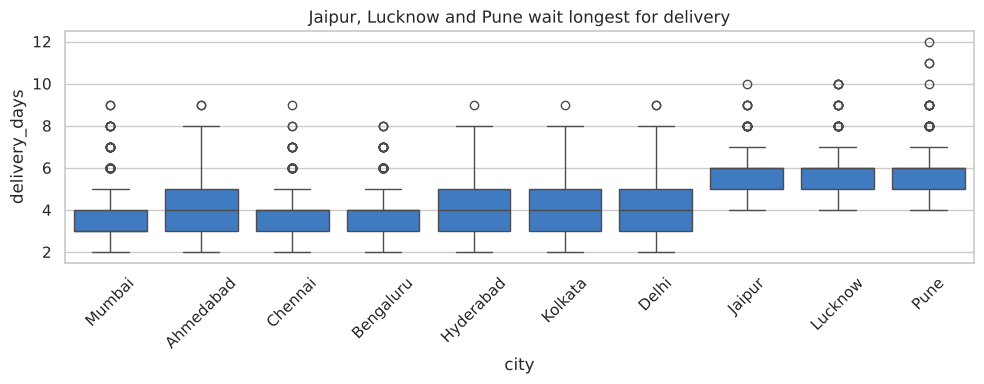

city
Pune       5.77
Lucknow    5.75
Jaipur     5.63
Name: delivery_days, dtype: float64

In [9]:
plt.figure(figsize=(10, 4))
city_order = df.groupby("city")["delivery_days"].median().sort_values().index
sns.boxplot(data=df, x="city", y="delivery_days", order=city_order, color=MAIN)
plt.title("Jaipur, Lucknow and Pune wait longest for delivery")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
df.groupby("city")["delivery_days"].mean().round(2).sort_values(ascending=False).head(3)